# 15 — Screen de modelos generativos del pase de decisiones de OpenKOS

**Autor:** Jason Sepúlveda S.
**Proyecto:** Evaluación experimental de la extracción automática y la representación
persistente de decisiones organizacionales frente a Recuperación Aumentada (RAG)
**Depende de:** [`14-jss-alineacion-experimento-a.ipynb`](14-jss-alineacion-experimento-a.ipynb) ·
[protocolo de alineación](../docs/protocols/alignment.md) ·
[ADR 0005](../docs/decisions/0005-adr-development-evaluation-split.md) ·
[ADR 0011](../docs/decisions/0011-adr-alineacion-rol-e-intervalos-del-experimento-a.md) ·
[prerregistro en OpenKOS](https://github.com/jasonssdev/openkos/blob/main/evals/transcript_decisions/PREREGISTRATION-model-screen.md)

---

## Qué se pregunta aquí

OpenKOS, el sistema que la tesis usa para extraer decisiones de las transcripciones de
reuniones, necesita un modelo generativo local (que corre en el propio computador, sin
servicio externo). Hay cuatro candidatos de la familia `qwen3`. Este notebook responde dos
preguntas: (1) **qué modelo conviene usar** para extraer decisiones, y (2) **si el puntaje de
la tesis sabe distinguir una buena extracción de una mala**, es decir, si sus resultados
significan algo. Importa porque el modelo elegido condiciona el costo y la validez del
Experimento A (la evaluación de la extracción automática de decisiones): una cifra de cobertura solo vale si el puntaje que la produce discrimina.

## Un ejemplo concreto

Una decisión extraída por `qwen3.6:27b` (corrida confirmatoria 1, reunión `ES2015a`) y la
decisión de referencia que le corresponde (`ES2015a.d02`, adjudicada por personas):

| | Objeto | Contenido |
|---|---|---|
| Extraída (inglés) | `selling price` | The selling price for the remote control will be twenty-five Euros. |
| Referencia (español) | precio de venta | fijar el precio de venta en 25 euros |

Ambas citan la misma frase de la reunión: «wanna make this um selling price of twenty five
Euros». El puntaje compara el texto «objeto: contenido» de cada par y lo cuenta como acierto
si su similitud supera un umbral (τ). Cabe notar que la extracción está en inglés y la referencia en
español: ese cruce de idiomas pesa en los resultados (sección 6.4).

> **Qué es esto y qué no es.** OpenKOS comparó los cuatro modelos (`qwen3:8b`, `qwen3:14b`,
> `qwen3.6:27b` y `qwen3.6:35b-a3b`) con una regla de selección **prerregistrada** antes de la
> primera corrida (se detalla más abajo). Este notebook vuelve a puntuar esas corridas con el
> **puntaje de la tesis** (`src/afg/evaluation/`) en vez de la copia que usa OpenKOS, aplica la
> misma regla y examina qué parte de la curva de τ discrimina. **No decide nada**: las
> preguntas de la sección 8 quedan para el equipo.
>
> **Límites que hay que tener presentes.** ES2015 y TS3009 son series de **desarrollo**:
> ninguna cifra de este notebook entra en una tabla de resultados
> ([ADR 0005](../docs/decisions/0005-adr-development-evaluation-split.md)). Nada aquí toca las
> series de evaluación: el cargador de corridas rechaza cualquier serie que no sea de
> desarrollo. El pase de decisiones es un componente de OpenKOS 0.6.0, no la configuración de
> extracción congelada del Experimento A. Con dos series de cuatro reuniones, 27 y 26
> decisiones de referencia, y 5 o 15 corridas por modelo, las cifras indican una dirección.

## Glosario

Los términos técnicos establecidos se mantienen tal cual; cada uno se explica aquí.

| Término | Qué significa en este notebook |
|---|---|
| Pase de decisiones | El paso de OpenKOS que lee una transcripción y entrega la lista de decisiones que encuentra. Cada una trae un objeto (`subject`), un contenido (`value`) y citas textuales de la reunión. |
| Corrida y *meeting-run* | Una corrida es una pasada completa de un modelo por las cuatro reuniones de una serie. Un *meeting-run* es el procesamiento de una reunión dentro de una corrida; está fallido si no deja una salida utilizable. |
| *Screen* | Primera ronda, barata (5 corridas por modelo y serie), para descartar modelos. |
| Confirmatoria | Segunda ronda, con 15 corridas **nuevas**, solo para el modelo que avanza y el modelo base. |
| Prerregistro | Documento fechado antes de la primera corrida que fija la regla de selección, para que no se ajuste después de ver los resultados. |
| Referencia | Las decisiones de cada serie anotadas por personas y adjudicadas (en inglés, *ground truth*); está en español. |
| Puntaje de la tesis y copia de OpenKOS | El primero es el código de la tesis (`src/afg/evaluation/`); la segunda es una reimplementación (`thesis_metric.py`) que OpenKOS usa en su propio informe. |
| Arnés de OpenKOS | El programa con que OpenKOS evalúa sus corridas. Decide los aciertos con su propia regla de solapamiento de evidencia, que la tesis no usa. |
| τ | Umbral de similitud (entre 0 y 1). Un par extraída–referencia cuenta como coincidencia si la similitud coseno de sus *embeddings* (`bge-m3`) es al menos τ. Con τ bajo se acepta casi cualquier parecido; con τ alto, solo textos casi iguales. |
| TP | Aciertos (*true positives*): decisiones extraídas emparejadas uno a uno con una de referencia. |
| Cobertura (*recall*) | TP dividido por las decisiones de referencia: qué parte de lo que había que encontrar se encontró. |
| Precisión | TP dividido por las decisiones extraídas: qué parte de lo extraído es correcto. |
| F1 | Media armónica de precisión y cobertura; resume ambas en un número. `dF1` es la diferencia de F1 medio entre un candidato y `qwen3:8b` con τ = 0,60. |
| `S` | Dispersión mín–máx: el mayor rango entre la corrida más baja y la más alta de los dos modelos comparados. Mide cuánto varía un modelo consigo mismo. |
| Control nulo | Puntuar la salida de un equipo contra la referencia de otro equipo: ningún acierto puede ser real, así que mide el parecido temático. |
| Techo entre idiomas | La similitud que alcanza una traducción fiel entre inglés y español; indica el máximo que puede esperarse de una extracción en inglés frente a una referencia en español. |

## Hoja de ruta

1. **Datos y método.** ¿Qué corridas se usan y cómo se puntúan?
2. **Validación.** ¿El puntaje de la tesis reproduce la cifra conocida de ES2015?
3. **Corridas del *screen* y de la confirmatoria.** ¿Coincide el puntaje de la tesis con la
   copia de OpenKOS, corrida a corrida?
4. **Tabla del *screen*.** ¿Qué resultado tiene cada modelo y qué dice la regla de selección?
5. **Tabla confirmatoria.** ¿Se sostiene la ventaja del modelo que avanzó con corridas nuevas?
6. **Gráficos.** ¿Qué parte de la curva de τ discrimina (curvas, control nulo, dispersión) y
   cuánto afecta el idioma?
7. **Hallazgos.** ¿Qué se concluye?
8. **Preguntas abiertas.** ¿Qué queda por decidir?

## Regla de selección prerregistrada

Un candidato avanza solo si, frente a `qwen3:8b` (el modelo base) y en **las dos** series,
cumple las cuatro condiciones:

1. **Mejora de F1:** su F1 medio con τ = 0,60 supera al del modelo base por al menos
   `max(0,05; S)`. Exige una mejora que no quede dentro del ruido entre corridas.
2. **Cobertura:** no baja respecto del modelo base. Evita ganar F1 solo por extraer menos.
3. **Fallas:** no falla más *meeting-runs* que `max(2; los del modelo base)`. Un modelo
   inestable no sirve aunque puntúe bien cuando responde.
4. **Volumen:** no produce más de 1,10 veces las decisiones por reunión del modelo base.
   Evita comprar cobertura inundando de decisiones.

Si avanzan varios, avanza el de mayor `dF1` medio entre las dos series.

---

# 1. Datos y método

**Qué se hace y por qué.** Se describen las corridas de entrada y el puntaje, para que cada cifra posterior se pueda rastrear a su origen.

Las corridas están copiadas, sin modificar, en `reports/experiment-a/model-screen-openkos/`
(procedencia en su [`PROCEDENCIA.md`](../reports/experiment-a/model-screen-openkos/PROCEDENCIA.md)):

- `screen/`: 5 corridas por modelo y serie de los cuatro modelos (160 meeting-runs);
- `confirm/`: 15 corridas **nuevas** de `qwen3.6:27b` (el que avanzó) y de `qwen3:8b`;
- `probes/`: una corrida de tiempo por modelo sobre TS3009, previa al prerregistro; el
  prerregistro la excluye de toda cifra, y aquí tampoco se puntúa.

Cada decisión del pase se convierte en una decisión extraída de la tesis con su `subject`
como objeto y su `value` como contenido (`afg.experiments.model_screen.load_pass_runs`), y se
puntúa con `score_series`: similitud coseno de *embeddings* `bge-m3` del par
«objeto: contenido», asignación uno a uno (algoritmo húngaro) y ámbito primario de la misma
reunión (ADR 0011). Se reporta el promedio por corrida y su rango mín–máx, como el
prerregistro. El pase guarda su evidencia como citas textuales y no como actos de diálogo,
así que no hay estratificación por rol.

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd

from afg.conditions.c1_retrieval import OllamaEmbedder
from afg.domain.decision import Decision
from afg.evaluation.alignment_analysis import embedding_similarity
from afg.evaluation.reference import load_series_reference
from afg.evaluation.scoring import interval_settings_from_config
from afg.experiments.extraction_runs import load_extraction_runs
from afg.experiments.model_screen import (
    advances,
    ceiling_pairs,
    ceiling_summary,
    curve_frame,
    curve_summary,
    guardrails_frame,
    language_counts,
    load_openkos_scores,
    load_pass_runs,
    mean_min_max,
    openkos_agreement,
    paired_similarity,
    relabel_series,
    reproduction_frame,
    score_curve,
    selection_rule,
    verdict_frame,
)
from afg.shared.config import load_experiments_config
from afg.shared.paths import AMI_DIR, EXPERIMENT_A_DIR, GOLD_DECISIONS_DIR, TRANSCRIPTS_DIR

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 60)

SCREEN_DIR = EXPERIMENT_A_DIR / "model-screen-openkos"
SERIES = ("ES2015", "TS3009")
TAU_GRID = load_experiments_config()["alignment"]["tau_grid"]
TABLE_TAUS = (0.50, 0.60, 0.70, 0.80)
BASELINE = "qwen3:8b"
MODELS = ("qwen3:8b", "qwen3:14b", "qwen3.6:27b", "qwen3.6:35b-a3b")
# Categorical slots in fixed order (validated palette); a model keeps its color everywhere.
COLORS = dict(zip(MODELS, ("#2a78d6", "#eb6834", "#1baf7a", "#eda100"), strict=True))
MARKERS = dict(zip(MODELS, ("o", "s", "^", "D"), strict=True))

# Guard: the run copies, the AMI summlink layer and the frozen transcripts must be present.
for path in (SCREEN_DIR, AMI_DIR, TRANSCRIPTS_DIR):
    if not path.exists():
        raise SystemExit(f"No se encontro {path}.\nVer notebooks/README.md (Reproducibilidad).")

reference_sets = {s: load_series_reference(s) for s in SERIES}
references = {s: list(r.decisions) for s, r in reference_sets.items()}

# Embeddings through the local Ollama model configured for alignment (cached per text).
_embedder = OllamaEmbedder.from_config()
_cache: dict[str, list[float]] = {}


def embed(texts):
    missing = [t for t in dict.fromkeys(texts) if t not in _cache]
    if missing:
        _cache.update(zip(missing, _embedder.embed(missing), strict=True))
    return [_cache[t] for t in texts]


similarity = embedding_similarity(embed)

for s, r in reference_sets.items():
    print(
        f"{s}: {len(r.decisions)} decisiones de referencia; excluidas {dict(r.excluded)}; "
        f"sin evidencia ubicada: {list(r.evidence_misses)}"
    )
print(f"Modelo de embeddings: {_embedder.model}; grilla de τ: {TAU_GRID}")

ES2015: 27 decisiones de referencia; excluidas {'no_decision': 3, 'compuesta': 2, 'descartar': 1, 'sin_soporte': 1}; sin evidencia ubicada: []
TS3009: 26 decisiones de referencia; excluidas {'no_decision': 1, 'compuesta': 2}; sin evidencia ubicada: ['TS3009b.d07']
Modelo de embeddings: bge-m3; grilla de τ: [0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9]


> **Nota técnica: una corrección previa del cargador.** El cargador de la referencia de la tesis no podía
> leer TS3009: en `TS3009.decisions.adjudicated.csv` los hijos `-1`, `-2`, `-3` de las dos
> filas `compuesta` (`TS3009c.d07` y `TS3009c.d11`) traen vacíos `meeting_id`,
> `source_sentence_id` y `evidence_text`, mientras que en ES2015 los hijos repiten los valores
> del padre. `load_reference` buscaba entonces la transcripción de una reunión vacía y fallaba.
> En esta misma rama se corrigió (commit `fix(evaluacion)`, con test): un campo vacío del hijo
> toma el valor de su padre `compuesta`. Con eso TS3009 carga 26 decisiones, 14 de ellas en la
> reunión c, igual que la copia de OpenKOS, que resolvía lo mismo derivando la reunión del
> identificador. La decisión `TS3009b.d07` queda sin evidencia ubicada, lo que no afecta a
> precisión, cobertura ni F1 (solo se usaría para el rol).

---

# 2. Validación: la cifra de ES2015 de la tesis

**Qué se hace y por qué.** Se reproduce una cifra ya conocida con el puntaje de la tesis, para confirmar que el cálculo funciona antes de usarlo sobre corridas nuevas.

Antes de puntuar nada nuevo, se reproduce con el puntaje de la tesis la cifra conocida: las
tres corridas de `es2015-explora-r3x` (extracción de OpenKOS 0.5.5 del
[notebook 12](12-jss-extraccion-openkos-es2015.ipynb)) dan, agrupadas, cobertura 0,52 con
τ = 0,60 y ámbito de la misma reunión ([notebook 14](14-jss-alineacion-experimento-a.ipynb),
sección 2). La copia de OpenKOS (`thesis_metric.py`) reportó 42 de 81 (0,519) en
`validation/`. Se comparan los TP agrupados en toda la grilla.

In [2]:
r3x = load_extraction_runs([EXPERIMENT_A_DIR / "es2015-explora-r3x"])
r3x_decisions = [[Decision(**d) for d in r.decisions] for r in r3x]
settings = interval_settings_from_config()
validation = json.loads(
    (SCREEN_DIR / "validation" / "es2015-r3x-thesis-metric.json").read_text(encoding="utf-8")
)["es2015-explora-r3x"]["curve"]
openkos_pooled = {round(c["tau"], 2): c["pooled"] for c in validation}

reproduction = reproduction_frame(
    references["ES2015"],
    r3x_decisions,
    similarity,
    taus=TAU_GRID,
    openkos_pooled=openkos_pooled,
    settings=settings,
    partition_of=lambda s: "development",
)
reproduction = reproduction.rename(
    columns={
        "tau": "τ",
        "tp_per_run": "TP por corrida (tesis)",
        "tp_pooled": "TP agrupado (tesis)",
        "tp_pooled_openkos": "TP agrupado (OpenKOS)",
        "n_extracted": "extraídas",
        "n_reference": "referencia",
        "recall": "cobertura (tesis)",
        "recall_openkos": "cobertura (OpenKOS)",
        "f1": "F1 agrupado (tesis)",
    }
).round(3)
reproduction

,τ,TP por corrida (tesis),TP agrupado (tesis),TP agrupado (OpenKOS),extraídas,referencia,cobertura (tesis),cobertura (OpenKOS),F1 agrupado (tesis)
0,0.50,"[21, 21, 21]",63,63,209,81,0.778,0.778,0.434
1,0.55,"[18, 18, 18]",54,54,209,81,0.667,0.667,0.372
2,0.60,"[14, 14, 14]",42,42,209,81,0.519,0.519,0.290
3,0.65,"[7, 9, 7]",23,23,209,81,0.284,0.284,0.159
4,0.70,"[3, 4, 3]",10,10,209,81,0.123,0.123,0.069
5,0.75,"[1, 1, 1]",3,3,209,81,0.037,0.037,0.021
6,0.80,"[0, 0, 0]",0,0,209,81,0.000,0.000,0.000
7,0.85,"[0, 0, 0]",0,0,209,81,0.000,0.000,0.000
8,0.90,"[0, 0, 0]",0,0,209,81,0.000,0.000,0.000


**Resultado — el puntaje de la tesis reproduce la cifra conocida de ES2015.**

El puntaje de la tesis reproduce la cifra: 14 aciertos en cada una de las tres
corridas con τ = 0,60, 42 de 81 agrupados, cobertura 0,519 (el 0,52 del notebook 14) y F1
agrupado 0,290. Los TP agrupados coinciden con los de la copia de OpenKOS en los nueve τ de
la grilla (63, 54, 42, 23, 10, 3, 0, 0 y 0).

---

# 3. Las corridas del *screen* y de la confirmatoria

**Qué se hace y por qué.** Se puntúan todas las corridas con el puntaje de la tesis en toda la grilla de τ, para tener la curva completa y no un solo punto.

Se cargan las corridas y se puntúan todas en la grilla completa de τ. Con el caché de
*embeddings*, cada texto distinto se embebe una sola vez.

In [3]:
screen_runs = load_pass_runs(sorted((SCREEN_DIR / "screen").glob("runs-pass-*.json")))
confirm_runs = load_pass_runs(sorted((SCREEN_DIR / "confirm").glob("runs-pass-*.json")))
probe_runs = load_pass_runs(sorted((SCREEN_DIR / "probes").glob("runs-pass-*.json")))

screen_points = score_curve(screen_runs, references, similarity, taus=TAU_GRID)
confirm_points = score_curve(confirm_runs, references, similarity, taus=TAU_GRID)

openkos_screen = load_openkos_scores(SCREEN_DIR / "screen" / "scored.json")
openkos_confirm = load_openkos_scores(SCREEN_DIR / "confirm" / "scored.json")

for label, runs in (("screen", screen_runs), ("confirmatoria", confirm_runs)):
    print(
        f"{label}: {len(runs)} corridas, {sum(len(r.meetings) for r in runs)} meeting-runs, "
        f"{sum(len(r.decisions) for r in runs)} decisiones extraídas"
    )
print(f"sondeos (no se puntúan): {[(r.model, r.series, round(r.wall_s)) for r in probe_runs]}")
print(f"textos embebidos: {len(_cache)}")

screen: 40 corridas, 160 meeting-runs, 2451 decisiones extraídas
confirmatoria: 60 corridas, 240 meeting-runs, 3747 decisiones extraídas
sondeos (no se puntúan): [('qwen3.6:27b', 'TS3009', 854), ('qwen3.6:35b-a3b', 'TS3009', 209), ('qwen3:14b', 'TS3009', 339), ('qwen3:8b', 'TS3009', 785)]
textos embebidos: 4328


## 3.1 ¿Coincide el puntaje de la tesis con la copia de OpenKOS?

**Qué se hace y por qué.** Se contrasta con el cálculo de OpenKOS, para saber si las cifras de su informe sirven tal cual para la tesis.

Se comparan los TP de cada corrida, modelo, serie y τ. Si las dos implementaciones son
equivalentes, las listas deben ser idénticas.

In [4]:
agreement = pd.concat(
    [
        openkos_agreement(screen_points, openkos_screen).assign(fase="screen"),
        openkos_agreement(confirm_points, openkos_confirm).assign(fase="confirmatoria"),
    ],
    ignore_index=True,
)
print(
    f"Combinaciones (fase, modelo, serie, τ) comparadas: {len(agreement)}; "
    f"con TP idénticos en todas las corridas: {int(agreement['equal'].sum())}"
)
agreement[~agreement["equal"]] if not agreement["equal"].all() else agreement.head(4)

Combinaciones (fase, modelo, serie, τ) comparadas: 108; con TP idénticos en todas las corridas: 108


,model,series,tau,tp_thesis,tp_openkos,equal,tp_difference,fase
0,qwen3.6:27b,ES2015,0.50,"[21, 21, 21, 19, 20]","[21, 21, 21, 19, 20]",True,0,screen
1,qwen3.6:27b,ES2015,0.55,"[18, 18, 18, 18, 16]","[18, 18, 18, 18, 16]",True,0,screen
2,qwen3.6:27b,ES2015,0.60,"[15, 16, 16, 16, 13]","[15, 16, 16, 16, 13]",True,0,screen
3,qwen3.6:27b,ES2015,0.65,"[11, 10, 12, 11, 12]","[11, 10, 12, 11, 12]",True,0,screen


**Resultado — las dos formas de puntuar dan lo mismo, así que las cifras de OpenKOS valen para la tesis.**

Las 108 combinaciones coinciden corrida a corrida: la misma lista de TP, y
por lo tanto la misma precisión, cobertura y F1. Las cifras del documento de resultados de
OpenKOS (`RESULTS-model-screen.md`) valen tal cual con el puntaje de la tesis. La única
diferencia práctica entre las dos implementaciones estaba en el cargador de TS3009
(sección 1), que la copia de OpenKOS ya resolvía de la misma forma. Quedan diferencias de
alcance, no de cifra: la copia programa su propio algoritmo húngaro en lugar de usar `scipy`
(el número de TP de una asignación de costo mínimo no depende de cómo se desempatan los
pares) y no implementa el ámbito de toda la serie, los roles ni el intervalo por reuniones
del ADR 0011.

---

# 4. Tabla del *screen* (n = 5)

**Qué se hace y por qué.** Se resume el desempeño de cada modelo en cada serie, para compararlos con las mismas medidas.

Por modelo y serie: cobertura (R) y F1 de la tesis con τ = 0,50, 0,60, 0,70 y 0,80 (promedio
de las 5 corridas y, entre paréntesis, mín–máx); la cobertura del arnés de OpenKOS (regla de
solapamiento de evidencia del propio arnés, que la tesis no implementa: se lee de su
`scored.json`); las meeting-runs fallidas sobre el total; decisiones por reunión; segundos
por corrida; e idioma de los textos extraídos (inglés / español / indeciso, por conteo de
palabras funcionales).

In [5]:
def mm(mean, low, high):
    return f"{mean:.3f} ({low:.3f}-{high:.3f})"


def screen_table(points, runs, openkos):
    summary = curve_summary(points)
    guards = guardrails_frame(runs).set_index(["model", "series"])
    rows = []
    for series in SERIES:
        for model in [m for m in MODELS if (m, series) in guards.index]:
            g = guards.loc[(model, series)]
            row = {"serie": series, "modelo": model}
            for tau in TABLE_TAUS:
                at = summary[
                    (summary.model == model)
                    & (summary.series == series)
                    & ((summary.tau - tau).abs() < 1e-9)
                ].iloc[0]
                row[f"R {tau:.2f}"] = mm(at.recall_mean, at.recall_min, at.recall_max)
                row[f"F1 {tau:.2f}"] = mm(at.f1_mean, at.f1_min, at.f1_max)
            harness = openkos[(model, series)]["harness_recall"]
            row["R arnés OpenKOS"] = mm(*mean_min_max(harness))
            row["fallas"] = f"{int(g.failed_meeting_runs)} de {int(g.meeting_runs)}"
            row["decisiones/reunión"] = round(g.decisions_per_meeting, 2)
            row["s/corrida"] = round(g.seconds_per_run, 1)
            row["idioma en/es/?"] = (
                f"{int(g.language_en)}/{int(g.language_es)}/{int(g.language_unknown)}"
            )
            rows.append(row)
    return pd.DataFrame(rows).set_index(["serie", "modelo"])


screen_table(screen_points, screen_runs, openkos_screen)

R 0.50              F1 0.50               R 0.60              F1 0.60               R 0.70              F1 0.70               R 0.80              F1 0.80  \
serie  modelo                                                                                                                                                                                    
ES2015 qwen3:8b         0.830 (0.778-0.926)  0.500 (0.438-0.581)  0.481 (0.444-0.556)  0.290 (0.250-0.349)  0.148 (0.111-0.222)  0.089 (0.067-0.140)  0.015 (0.000-0.037)  0.009 (0.000-0.023)   
       qwen3:14b        0.926 (0.926-0.926)  0.658 (0.602-0.694)  0.548 (0.444-0.630)  0.387 (0.324-0.421)  0.059 (0.000-0.074)  0.042 (0.000-0.056)  0.022 (0.000-0.037)  0.016 (0.000-0.028)   
       qwen3.6:27b      0.756 (0.704-0.778)  0.651 (0.603-0.712)  0.563 (0.481-0.593)  0.485 (0.413-0.542)  0.222 (0.185-0.296)  0.191 (0.159-0.254)  0.022 (0.000-0.037)  0.019 (0.000-0.032)   
       qwen3.6:35b-a3b  0.919 (0.889-0.963)  0.650 (0.543-0.738)  0.652 (0.593-0.704)  0.461 (0.413-0.554)  0.252 (0.111-0.296)  0.177 (0.083-0.246)  0.015 (0.000-0.037)  0.011 (0.000-0.031)   
TS3009 qwen3:8b         0.992 (0.962-1.000)  0.455 (0.431-0.486)  0.654 (0.577-0.692)  0.300 (0.252-0.336)  0.215 (0.154-0.308)  0.099 (0.067-0.140)  0.015 (0.000-0.077)  0.007 (0.000-0.035)   
       qwen3:14b        0.992 (0.962-1.000)  0.624 (0.598-0.642)  0.785 (0.692-0.846)  0.493 (0.462-0.543)  0.277 (0.192-0.346)  0.174 (0.120-0.222)  0.023 (0.000-0.038)  0.014 (0.000-0.025)   
       qwen3.6:27b      1.000 (1.000-1.000)  0.567 (0.510-0.612)  0.808 (0.692-0.885)  0.457 (0.379-0.512)  0.369 (0.308-0.462)  0.211 (0.157-0.279)  0.031 (0.000-0.077)  0.017 (0.000-0.043)   
       qwen3.6:35b-a3b  1.000 (1.000-1.000)  0.483 (0.477-0.495)  0.838 (0.769-0.885)  0.405 (0.377-0.438)  0.354 (0.231-0.423)  0.171 (0.110-0.210)  0.038 (0.000-0.077)  0.019 (0.000-0.037)   

                            R arnés OpenKOS   fallas  decisiones/reunión  s/corrida idioma en/es/?  
serie  modelo                                                                                       
ES2015 qwen3:8b         0.341 (0.222-0.407)  0 de 20               15.70      167.5        314/0/0  
       qwen3:14b        0.393 (0.296-0.444)  0 de 20               12.30      215.9        246/0/0  
       qwen3.6:27b      0.452 (0.407-0.519)  0 de 20                8.95      580.8        179/0/0  
       qwen3.6:35b-a3b  0.541 (0.444-0.630)  0 de 20               12.55       89.6        251/0/0  
TS3009 qwen3:8b         0.123 (0.077-0.154)  0 de 20               21.90      268.2        436/0/2  
       qwen3:14b        0.185 (0.154-0.231)  0 de 20               14.20      222.5        284/0/0  
       qwen3.6:27b      0.231 (0.192-0.308)  0 de 20               16.55      882.6        331/0/0  
       qwen3.6:35b-a3b  0.238 (0.192-0.346)  0 de 20               20.40      187.1        408/0/0

## 4.1 Regla de selección sobre el *screen*

**Qué se hace y por qué.** Se aplica la regla prerregistrada (ver «Regla de selección prerregistrada», arriba) a los datos, para ver qué modelo avanza sin elegir a conveniencia.

Cada candidato frente a `qwen3:8b`, por serie: `dF1` es la diferencia de F1 medio con
τ = 0,60; `S`, la mayor dispersión mín–máx de los dos; la condición 1 exige
`dF1 ≥ max(0,05; S)`. Si avanzan varios, avanza el de mayor `dF1` medio entre las dos series.

In [6]:
def rule_table(checks):
    return pd.DataFrame(
        [
            {
                "candidato": c.candidate,
                "serie": c.series,
                "F1 cand.": round(c.f1_candidate, 3),
                "F1 base": round(c.f1_baseline, 3),
                "dF1": round(c.d_f1, 3),
                "exigido max(0,05; S)": round(c.margin_needed, 3),
                "1 margen": c.margin_ok,
                "R cand.": round(c.recall_candidate, 3),
                "R base": round(c.recall_baseline, 3),
                "2 cobertura": c.recall_ok,
                "fallas cand./base": f"{c.failures_candidate}/{c.failures_baseline}",
                "3 fallas": c.failures_ok,
                "vol. cand.": round(c.volume_candidate, 2),
                "tope 1,10 x vol. base": round(c.volume_cap, 2),
                "4 volumen": c.volume_ok,
            }
            for c in checks
        ]
    )


screen_checks = {
    m: selection_rule(screen_points, screen_runs, candidate=m, baseline=BASELINE)
    for m in MODELS
    if m != BASELINE
}
display(rule_table([c for checks in screen_checks.values() for c in checks]))
verdict = verdict_frame(screen_checks).rename(
    columns={"candidate": "candidato", "advances": "avanza", "d_f1_mean": "dF1 medio"}
)
verdict["dF1 medio"] = verdict["dF1 medio"].round(3)
verdict

,candidato,serie,F1 cand.,F1 base,dF1,"exigido max(0,05; S)",1 margen,R cand.,R base,2 cobertura,fallas cand./base,3 fallas,vol. cand.,"tope 1,10 x vol. base",4 volumen
0,qwen3:14b,ES2015,0.387,0.29,0.097,0.099,False,0.548,0.481,True,0/0,True,12.30,17.27,True
1,qwen3:14b,TS3009,0.493,0.30,0.192,0.084,True,0.785,0.654,True,0/0,True,14.20,24.09,True
2,qwen3.6:27b,ES2015,0.485,0.29,0.194,0.130,True,0.563,0.481,True,0/0,True,8.95,17.27,True
3,qwen3.6:27b,TS3009,0.457,0.30,0.157,0.133,True,0.808,0.654,True,0/0,True,16.55,24.09,True
4,qwen3.6:35b-a3b,ES2015,0.461,0.29,0.171,0.141,True,0.652,0.481,True,0/0,True,12.55,17.27,True
5,qwen3.6:35b-a3b,TS3009,0.405,0.30,0.105,0.084,True,0.838,0.654,True,0/0,True,20.40,24.09,True


,candidato,avanza,dF1 medio
0,qwen3.6:27b,True,0.176
1,qwen3:14b,False,0.145
2,qwen3.6:35b-a3b,True,0.138


**Resultado — con la regla prerregistrada avanza `qwen3.6:27b`.**

`qwen3.6:27b` y `qwen3.6:35b-a3b` cumplen las cuatro condiciones en las dos
series, y avanza `qwen3.6:27b` por su mayor dF1 medio (+0,176 frente a +0,138).
`qwen3:14b` queda fuera por la condición 1 en ES2015: su dF1 es 0,097 y se exigían 0,099 (le
faltan 0,002), aunque su dF1 medio entre las dos series (+0,145) supera al de
`qwen3.6:35b-a3b`. Es la regla operando como se registró, no evidencia de que `qwen3:14b`
sea peor. Ningún modelo falló una meeting-run en el *screen* (0 de 20 en todos los casos).

---

# 5. Tabla confirmatoria (n = 15): `qwen3.6:27b` frente a `qwen3:8b`

**Qué se hace y por qué.** Se repite la comparación con corridas nuevas del modelo que avanzó, porque el *screen* tiene pocas corridas y el ganador de una selección tiende a verse mejor de lo que es.

Corridas nuevas, ninguna reutilizada del *screen* (las del ganador arrastran sesgo de
selección), con la misma configuración congelada y el mismo `qwen3:8b` como comparador,
también con 15 corridas nuevas.

In [7]:
display(screen_table(confirm_points, confirm_runs, openkos_confirm))
confirm_checks = selection_rule(
    confirm_points, confirm_runs, candidate="qwen3.6:27b", baseline=BASELINE
)
display(rule_table(confirm_checks))
print(f"qwen3.6:27b confirma: {advances(confirm_checks)}")
for r in confirm_runs:
    for meeting, failure in r.failures:
        print(f"  falla: {r.model} {meeting} corrida {r.run}: {failure}")

R 0.50              F1 0.50               R 0.60              F1 0.60               R 0.70              F1 0.70               R 0.80              F1 0.80  \
serie  modelo                                                                                                                                                                                
ES2015 qwen3:8b     0.822 (0.778-0.926)  0.502 (0.429-0.575)  0.474 (0.407-0.519)  0.289 (0.255-0.322)  0.136 (0.037-0.222)  0.083 (0.021-0.138)  0.010 (0.000-0.037)  0.006 (0.000-0.025)   
       qwen3.6:27b  0.800 (0.667-0.926)  0.654 (0.514-0.762)  0.575 (0.481-0.667)  0.470 (0.394-0.554)  0.225 (0.148-0.296)  0.183 (0.123-0.250)  0.035 (0.000-0.074)  0.028 (0.000-0.063)   
TS3009 qwen3:8b     0.987 (0.962-1.000)  0.462 (0.435-0.486)  0.646 (0.538-0.808)  0.303 (0.248-0.400)  0.226 (0.154-0.308)  0.106 (0.070-0.138)  0.010 (0.000-0.038)  0.005 (0.000-0.018)   
       qwen3.6:27b  1.000 (1.000-1.000)  0.583 (0.515-0.642)  0.818 (0.692-0.923)  0.474 (0.429-0.522)  0.392 (0.308-0.538)  0.228 (0.174-0.308)  0.051 (0.000-0.115)  0.030 (0.000-0.065)   

                        R arnés OpenKOS   fallas  decisiones/reunión  s/corrida idioma en/es/?  
serie  modelo                                                                                   
ES2015 qwen3:8b     0.341 (0.259-0.407)  1 de 60               15.43      165.7        921/0/5  
       qwen3.6:27b  0.457 (0.370-0.519)  0 de 60                9.80      597.6        588/0/0  
TS3009 qwen3:8b     0.146 (0.077-0.192)  6 de 60               21.32      488.8       1278/0/1  
       qwen3.6:27b  0.205 (0.115-0.346)  4 de 60               15.90      894.7        954/0/0

,candidato,serie,F1 cand.,F1 base,dF1,"exigido max(0,05; S)",1 margen,R cand.,R base,2 cobertura,fallas cand./base,3 fallas,vol. cand.,"tope 1,10 x vol. base",4 volumen
0,qwen3.6:27b,ES2015,0.470,0.289,0.181,0.160,True,0.575,0.474,True,0/1,True,9.8,16.98,True
1,qwen3.6:27b,TS3009,0.474,0.303,0.172,0.152,True,0.818,0.646,True,4/6,True,15.9,23.45,True


qwen3.6:27b confirma: True
  falla: qwen3.6:27b TS3009c corrida 5: decision_pass: unparseable reply
  falla: qwen3.6:27b TS3009b corrida 10: decision_pass: unparseable reply
  falla: qwen3.6:27b TS3009b corrida 12: decision_pass: unparseable reply
  falla: qwen3.6:27b TS3009b corrida 14: decision_pass: unparseable reply
  falla: qwen3:8b ES2015c corrida 6: decision_pass: unparseable reply
  falla: qwen3:8b TS3009a corrida 3: decision_pass: OllamaGenerationCapped
  falla: qwen3:8b TS3009a corrida 4: decision_pass: OllamaGenerationCapped
  falla: qwen3:8b TS3009a corrida 5: decision_pass: OllamaGenerationCapped
  falla: qwen3:8b TS3009a corrida 8: decision_pass: OllamaGenerationCapped
  falla: qwen3:8b TS3009a corrida 9: decision_pass: OllamaGenerationCapped
  falla: qwen3:8b TS3009a corrida 13: decision_pass: OllamaGenerationCapped


**Resultado — las corridas nuevas confirman a `qwen3.6:27b`, a cambio de mucho más tiempo.**

Con 15 corridas nuevas por modelo, `qwen3.6:27b` confirma: dF1 de +0,181 en
ES2015 (exigido 0,160) y +0,172 en TS3009 (exigido 0,152); cobertura mayor (0,575 frente a
0,474 y 0,818 frente a 0,646); fallas 0 frente a 1 y 4 frente a 6; y 9,80 y 15,90 decisiones
por reunión, bajo los topes de 16,98 y 23,45. Las ganancias son del mismo tamaño que en el
*screen* (+0,194 y +0,157). Con 15 corridas los rangos mín–máx son más anchos que con 5 (en
ES2015, `S` pasa de 0,130 a 0,160): cinco corridas subestiman la variación entre corridas.
El costo es el tiempo: `qwen3.6:27b` tarda 597,6 s por corrida en ES2015 frente a 165,7 s de
`qwen3:8b` (3,6 veces) y 894,7 s frente a 488,8 s en TS3009 (1,8 veces, con el tiempo del
8b inflado por sus fallas por tope de generación).

---

# 6. Gráficos

**Qué se hace y por qué.** Se miran las curvas completas de τ, el control nulo, la dispersión y el efecto del idioma, para saber qué parte del puntaje es informativa.

## 6.1 Curvas de τ por modelo y serie (*screen*, n = 5)

Se grafica cada métrica contra τ para ver dónde se separan los modelos.

Línea: promedio de las 5 corridas; banda: mín–máx. La línea punteada vertical marca el
τ = 0,60 de la regla.

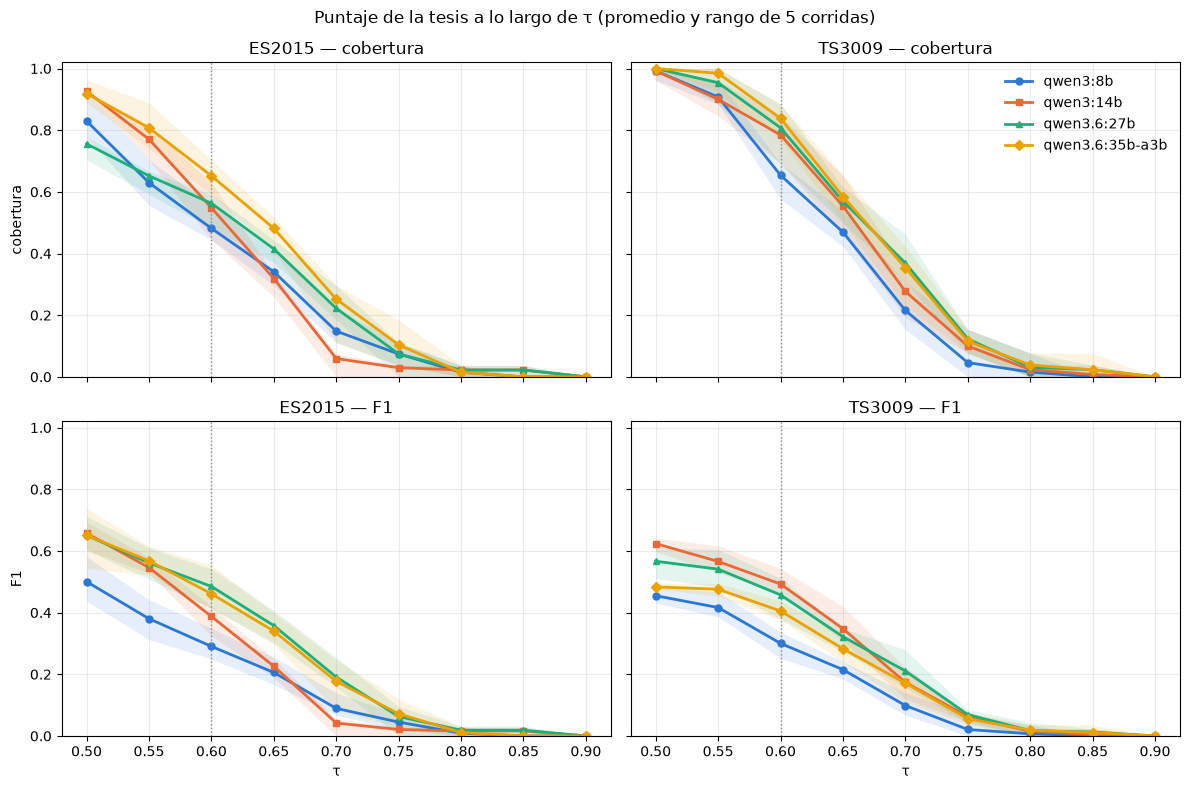

In [8]:
screen_curve = curve_summary(screen_points)
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey="row")
for col, series in enumerate(SERIES):
    for row, metric in enumerate(("recall", "f1")):
        ax = axes[row, col]
        for model in MODELS:
            d = screen_curve[(screen_curve.model == model) & (screen_curve.series == series)]
            ax.plot(
                d.tau,
                d[f"{metric}_mean"],
                color=COLORS[model],
                marker=MARKERS[model],
                markersize=5,
                linewidth=2,
                label=model,
            )
            ax.fill_between(
                d.tau,
                d[f"{metric}_min"],
                d[f"{metric}_max"],
                color=COLORS[model],
                alpha=0.12,
                linewidth=0,
            )
        ax.axvline(0.60, color="#888888", linestyle=":", linewidth=1)
        ax.set_title(f"{series} — {'cobertura' if metric == 'recall' else 'F1'}")
        ax.grid(alpha=0.25)
        ax.set_ylim(0, 1.02)
        if row == 1:
            ax.set_xlabel("τ")
axes[0, 0].set_ylabel("cobertura")
axes[1, 0].set_ylabel("F1")
axes[0, 1].legend(frameon=False, loc="upper right")
fig.suptitle("Puntaje de la tesis a lo largo de τ (promedio y rango de 5 corridas)")
fig.tight_layout()
plt.show()

**Lectura — el puntaje solo separa a los modelos en un tramo intermedio de τ, y el orden cambia a lo largo de la curva.**

Con τ = 0,50 la cobertura está cerca del máximo para casi todos los modelos
(0,76 a 1,00) y no los ordena; entre 0,55 y 0,70 los modelos se separan; desde 0,80 todo cae
a casi cero (cobertura media de 0,05 o menos). El orden **cambia** a lo largo de la curva, como el
protocolo exige declarar: en ES2015, `qwen3:14b` tiene el mayor F1 con 0,50 y queda bajo
`qwen3:8b` con 0,70 (0,042 frente a 0,089); en TS3009, `qwen3:14b` lidera F1 entre 0,50 y
0,65 y `qwen3.6:27b` en 0,70 y 0,75. `qwen3:8b` tiene el menor F1 entre 0,50 y 0,65 en las
dos series.

## 6.2 Control nulo entre reuniones de otro equipo

Se mide cuánto del puntaje es parecido temático y no acierto real.

¿Cuánto de la cobertura es encontrar *las* decisiones de la reunión, y cuánto es parecido
temático? ES2015 y TS3009 son dos equipos distintos que diseñan el mismo control remoto en
cuatro reuniones. El control nulo puntúa la salida de una serie contra la referencia de la
otra, reunión a reunión (a→a, b→b, …; `relabel_series`): ninguna de esas decisiones puede ser
un acierto real. Se hace en los dos sentidos (salida de ES2015 contra la referencia de
TS3009, y la inversa), con las corridas del *screen* y las de la confirmatoria. El rango útil
de τ es donde la curva real se separa de la nula.

In [9]:
def null_points(runs):
    other = {"ES2015": "TS3009", "TS3009": "ES2015"}
    moved = [relabel_series(r, other[r.series]) for r in runs]
    return score_curve(moved, references, similarity, taus=TAU_GRID)


null_screen = curve_summary(null_points(screen_runs))
null_confirm = curve_summary(null_points(confirm_runs))
real_confirm = curve_summary(confirm_points)


def null_table(real, null, label):
    rows = []
    for _, n in null.iterrows():
        if round(n.tau, 2) not in (0.50, 0.60, 0.70, 0.80):
            continue
        r = real[(real.model == n.model) & (real.series == n.series) & (real.tau == n.tau)].iloc[0]
        rows.append(
            {
                "fase": label,
                "referencia": n.series,
                "salida de": "TS3009" if n.series == "ES2015" else "ES2015",
                "modelo": n.model,
                "τ": n.tau,
                "R real": round(r.recall_mean, 3),
                "R nulo": round(n.recall_mean, 3),
                "R nulo mín-máx": f"{n.recall_min:.3f}-{n.recall_max:.3f}",
                "F1 real": round(r.f1_mean, 3),
                "F1 nulo": round(n.f1_mean, 3),
            }
        )
    return pd.DataFrame(rows)


nulls = pd.concat(
    [
        null_table(screen_curve, null_screen, "screen"),
        null_table(real_confirm, null_confirm, "confirmatoria"),
    ],
    ignore_index=True,
)
display(
    nulls.pivot_table(
        index=["fase", "referencia", "modelo"], columns="τ", values=["R real", "R nulo"]
    ).round(3)
)
print("Con τ = 0,60, F1 real frente a F1 nulo:")
nulls[nulls["τ"] == 0.60][["fase", "referencia", "modelo", "F1 real", "F1 nulo", "R nulo mín-máx"]]

R nulo                      R real                     
τ                                           0.5    0.6    0.7    0.8    0.5    0.6    0.7    0.8
fase          referencia modelo                                                                 
confirmatoria ES2015     qwen3.6:27b      0.862  0.277  0.040  0.012  0.800  0.575  0.225  0.035
                         qwen3:8b         0.956  0.338  0.022  0.000  0.822  0.474  0.136  0.010
              TS3009     qwen3.6:27b      0.872  0.377  0.110  0.000  1.000  0.818  0.392  0.051
                         qwen3:8b         0.967  0.305  0.003  0.000  0.987  0.646  0.226  0.010
screen        ES2015     qwen3.6:27b      0.881  0.311  0.030  0.022  0.756  0.563  0.222  0.022
                         qwen3.6:35b-a3b  0.904  0.341  0.067  0.000  0.919  0.652  0.252  0.015
                         qwen3:14b        0.815  0.207  0.015  0.000  0.926  0.548  0.059  0.022
                         qwen3:8b         0.948  0.311  0.015  0.000  0.830  0.481  0.148  0.015
              TS3009     qwen3.6:27b      0.800  0.354  0.115  0.000  1.000  0.808  0.369  0.031
                         qwen3.6:35b-a3b  0.915  0.354  0.046  0.000  1.000  0.838  0.354  0.038
                         qwen3:14b        0.908  0.331  0.069  0.000  0.992  0.785  0.277  0.023
                         qwen3:8b         0.954  0.315  0.023  0.000  0.992  0.654  0.215  0.015

Con τ = 0,60, F1 real frente a F1 nulo:


,fase,referencia,modelo,F1 real,F1 nulo,R nulo mín-máx
1,screen,ES2015,qwen3.6:27b,0.485,0.180,0.222-0.407
5,screen,TS3009,qwen3.6:27b,0.457,0.297,0.308-0.423
9,screen,ES2015,qwen3.6:35b-a3b,0.461,0.169,0.296-0.370
13,screen,TS3009,qwen3.6:35b-a3b,0.405,0.242,0.269-0.385
17,screen,ES2015,qwen3:14b,0.387,0.133,0.148-0.296
21,screen,TS3009,qwen3:14b,0.493,0.229,0.269-0.385
25,screen,ES2015,qwen3:8b,0.290,0.147,0.259-0.370
29,screen,TS3009,qwen3:8b,0.300,0.185,0.269-0.385
33,confirmatoria,ES2015,qwen3.6:27b,0.470,0.164,0.148-0.444
37,confirmatoria,TS3009,qwen3.6:27b,0.474,0.301,0.308-0.462


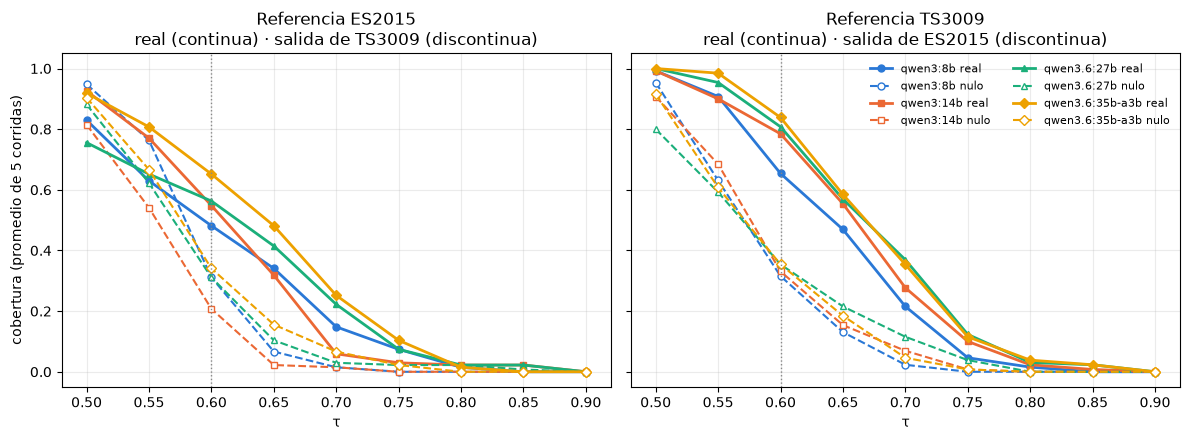

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, series in zip(axes, SERIES, strict=True):
    for model in MODELS:
        d = screen_curve[(screen_curve.model == model) & (screen_curve.series == series)]
        n = null_screen[(null_screen.model == model) & (null_screen.series == series)]
        ax.plot(
            d.tau,
            d.recall_mean,
            color=COLORS[model],
            marker=MARKERS[model],
            markersize=5,
            linewidth=2,
            label=f"{model} real",
        )
        ax.plot(
            n.tau,
            n.recall_mean,
            color=COLORS[model],
            marker=MARKERS[model],
            markersize=5,
            linewidth=1.5,
            linestyle="--",
            markerfacecolor="white",
            label=f"{model} nulo",
        )
    ax.axvline(0.60, color="#888888", linestyle=":", linewidth=1)
    other = "TS3009" if series == "ES2015" else "ES2015"
    ax.set_title(f"Referencia {series}\nreal (continua) · salida de {other} (discontinua)")
    ax.set_xlabel("τ")
    ax.grid(alpha=0.25)
axes[0].set_ylabel("cobertura (promedio de 5 corridas)")
axes[1].legend(frameon=False, fontsize=8, ncol=2)
fig.tight_layout()
plt.show()

**Lectura — con τ = 0,50 el puntaje no distingue haber encontrado las decisiones de haber hablado del mismo tema; el tramo informativo es de τ = 0,60 a 0,70.**

Con τ = 0,50 la cobertura nula (la salida de otro equipo) es de 0,80 a 0,97,
y en ES2015 llega a superar a la real (`qwen3:8b`: 0,948 nula frente a 0,830 real;
`qwen3.6:27b`: 0,881 frente a 0,756): **con τ = 0,50 el puntaje no distingue haber
encontrado las decisiones de la reunión de haber hablado del mismo producto**. Con
τ = 0,60 el piso nulo es de 0,21 a 0,38, con un promedio de las 12 combinaciones de **0,32**, y todas las
curvas reales quedan por encima (0,47 a 0,84); pero el piso es alto: para `qwen3:8b` en
ES2015, 0,481 real frente a 0,311 nula, y el F1 nulo de `qwen3.6:27b` sobre la referencia de
TS3009 (0,297) iguala al F1 real de `qwen3:8b` (0,300). Con τ = 0,70 el nulo cae a entre
0,00 y 0,12 mientras la real queda entre 0,06 y 0,39: la separación relativa es la mayor de
la curva, aunque con cifras reales ya bajas (`qwen3:14b` en ES2015: 0,059 frente a 0,015).
Desde 0,80 real y nula valen casi cero. El tramo en que las curvas se separan es, entonces,
de τ = 0,60 a 0,70. Las diferencias **entre modelos** con τ = 0,60 siguen siendo
interpretables (la misma referencia y el mismo piso para todos); las cifras **absolutas** con
τ = 0,60 sobrestiman cuántas decisiones de referencia se encontraron.

## 6.3 Dispersión entre corridas con τ = 0,60

Se compara la variación entre corridas de cada modelo, para ver si las diferencias superan el ruido.

Cada punto es una corrida; la caja resume las corridas de un modelo. Izquierda, el *screen*
(5 corridas por modelo); derecha, la confirmatoria (15). La línea gris discontinua es el
piso nulo medio de esa serie (sección 6.2, todos los modelos de la fase).

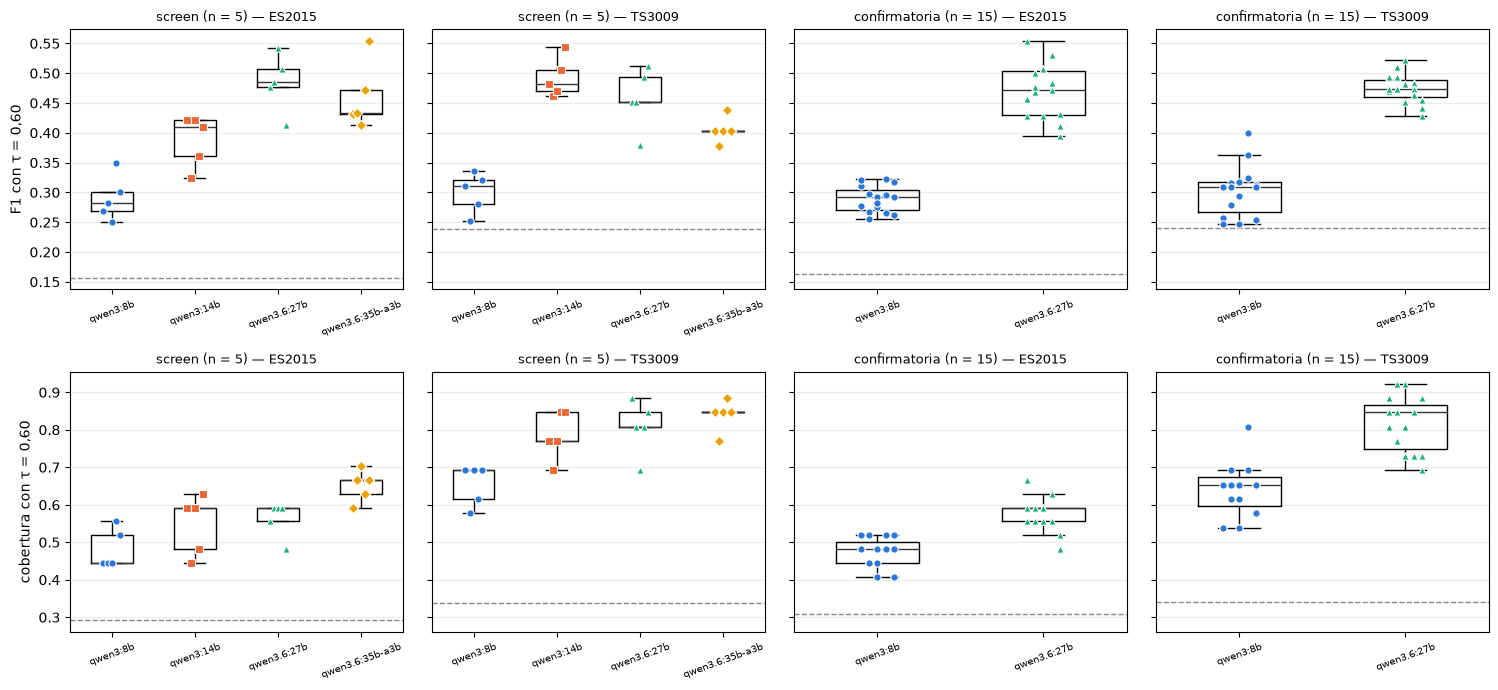

In [11]:
frame = pd.concat(
    [
        curve_frame(screen_points).assign(fase="screen (n = 5)"),
        curve_frame(confirm_points).assign(fase="confirmatoria (n = 15)"),
    ]
)
frame = frame[(frame.tau - 0.60).abs() < 1e-9]
null_floor = {
    ("screen (n = 5)", s): null_screen[(null_screen.series == s) & (null_screen.tau == 0.60)]
    for s in SERIES
} | {
    ("confirmatoria (n = 15)", s): null_confirm[
        (null_confirm.series == s) & (null_confirm.tau == 0.60)
    ]
    for s in SERIES
}

fig, axes = plt.subplots(2, 4, figsize=(15, 7), sharey="row")
for row, metric in enumerate(("f1", "recall")):
    for col, (phase, series) in enumerate(
        [(p, s) for p in ("screen (n = 5)", "confirmatoria (n = 15)") for s in SERIES]
    ):
        ax = axes[row, col]
        d = frame[(frame.fase == phase) & (frame.series == series)]
        models = [m for m in MODELS if m in set(d.model)]
        ax.boxplot(
            [d[d.model == m][metric] for m in models],
            positions=range(len(models)),
            widths=0.5,
            showfliers=False,
            medianprops={"color": "#333333"},
        )
        for i, m in enumerate(models):
            v = d[d.model == m][metric].to_numpy()
            ax.scatter(
                [i + 0.05 * ((k % 5) - 2) for k in range(len(v))],
                v,
                color=COLORS[m],
                marker=MARKERS[m],
                s=28,
                zorder=3,
                edgecolor="white",
                linewidth=0.8,
            )
        floor = null_floor[(phase, series)][f"{metric}_mean"].mean()
        ax.axhline(floor, color="#888888", linestyle="--", linewidth=1)
        ax.set_xticks(range(len(models)), models, fontsize=7, rotation=20)
        ax.set_title(f"{phase} — {series}", fontsize=9)
        ax.grid(axis="y", alpha=0.25)
    axes[row, 0].set_ylabel("F1 con τ = 0,60" if metric == "f1" else "cobertura con τ = 0,60")
fig.tight_layout()
plt.show()

**Lectura — la ventaja de `qwen3.6:27b` sobre `qwen3:8b` en F1 no se explica por la variación entre corridas.**

En el *screen*, las cajas de F1 de los tres candidatos se solapan entre sí
(en TS3009 el de mayor F1 es `qwen3:14b`) pero ninguna toca la de `qwen3:8b`. En la
confirmatoria, el F1 de `qwen3.6:27b` y el de `qwen3:8b` no se solapan en ninguna serie
(ES2015: 0,394–0,554 frente a 0,255–0,322; TS3009: 0,429–0,522 frente a 0,248–0,400); la
cobertura sí se solapa (ES2015: 0,481–0,667 frente a 0,407–0,519), así que parte de la
ganancia en F1 es precisión, por producir menos decisiones por reunión. Todas las corridas
de todos los modelos quedan sobre el piso nulo medio.

## 6.4 Techo entre idiomas

Se estima cuánto puede acercarse una traducción fiel a la referencia, para saber si el idioma limita el puntaje.

Todas las extracciones están en inglés y la referencia en español. Para medir cuánto puede
acercarse una traducción fiel, se embebe la oración abstractiva de AMI (en inglés) de la que
se anotó cada decisión de referencia frente a su propio «objeto: contenido» en español
(`ceiling_pairs`; filas con oración, como en el diagnóstico de OpenKOS).

Idioma de las extracciones (screen + confirmatoria): {'en': 6190, 'es': 0, 'unknown': 8}


,n,mediana,mínimo,máximo,≥ 0.60,≥ 0.70,≥ 0.80
serie,,,,,,,
ES2015,27,0.689,0.437,0.838,22,13,3
TS3009,21,0.724,0.511,0.853,20,12,3


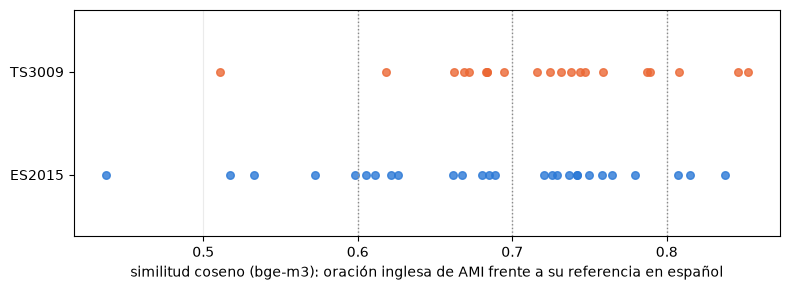

In [12]:
print(
    f"Idioma de las extracciones (screen + confirmatoria): "
    f"{language_counts(screen_runs + confirm_runs)}"
)
CEILING_THRESHOLDS = (0.60, 0.70, 0.80)
ceiling_sims = {}
for series in SERIES:
    pairs = ceiling_pairs(GOLD_DECISIONS_DIR / f"{series}.decisions.adjudicated.csv")
    ceiling_sims[series] = paired_similarity(
        similarity, [a for a, _ in pairs], [b for _, b in pairs]
    )
ceiling = pd.DataFrame(
    [{"serie": s, "similitud": v} for s, values in ceiling_sims.items() for v in values]
)
summary = ceiling_summary(ceiling_sims, thresholds=CEILING_THRESHOLDS).rename(
    columns={"median": "mediana", "min": "mínimo", "max": "máximo"}
    | {f"count_ge_{t:.2f}": f"≥ {t:.2f}" for t in CEILING_THRESHOLDS}
)
summary.index.name = "serie"
display(summary.round(3))
fig, ax = plt.subplots(figsize=(8, 3))
for i, series in enumerate(SERIES):
    v = ceiling[ceiling.serie == series].similitud
    ax.scatter(v, [i] * len(v), color=("#2a78d6", "#eb6834")[i], s=30, alpha=0.8)
for t in (0.60, 0.70, 0.80):
    ax.axvline(t, color="#888888", linestyle=":", linewidth=1)
ax.set_yticks([0, 1], SERIES)
ax.set_xlabel("similitud coseno (bge-m3): oración inglesa de AMI frente a su referencia en español")
ax.set_ylim(-0.6, 1.6)
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

**Lectura — con τ desde 0,80 la cobertura colapsa por la diferencia de idioma, no por los modelos.**

De 6.198 textos extraídos, 6.190 se leen como inglés, 8 como indecisos y
ninguno como español; la referencia está en español. La oración inglesa de AMI frente a su
propia referencia en español da una similitud mediana de 0,689 (ES2015, 27 decisiones) y
0,724 (TS3009, 21: los hijos de las filas compuestas no traen oración); solo 3 de 27 y 3 de
21 llegan a 0,80. Si ni la oración de origen alcanza 0,80, una extracción en inglés
tampoco: **el colapso desde τ = 0,80 lo produce la diferencia de idioma, no los modelos**.

---

# 7. Hallazgos

1. **Las dos formas de puntuar coinciden.** El puntaje de la tesis y la copia de OpenKOS dan
   exactamente los mismos TP (108 de 108 combinaciones) y reproducen la cifra de ES2015 (0,519 con τ = 0,60). Para
   llegar ahí hubo que corregir el cargador de la referencia de TS3009 (sección 1).
2. **Con τ = 0,50 el puntaje no sirve para distinguir.** Dicho de otro modo, τ = 0,50 no
   discrimina: la cobertura nula (salida de otro equipo contra esta
   referencia) es de 0,80 a 0,97, igual o mayor que la real en varios modelos.
3. **Parte de la cobertura con τ = 0,60 es solo parecido temático.** El piso nulo con
   τ = 0,60 es de alrededor de 0,32 (0,21 a 0,38 según el modelo y el
   sentido del cruce). Todas las corridas reales lo superan, pero las cifras absolutas con
   τ = 0,60 incluyen parecido temático; el tramo de τ en que real y nulo se separan es de
   0,60 a 0,70.
4. **El idioma, y no los modelos, explica la caída desde τ = 0,80.** La cobertura colapsa
   porque toda la extracción está en inglés y la referencia en español. Ningún texto extraído está en español, y la oración inglesa de
   origen de cada decisión alcanza 0,80 contra su referencia solo en 3 de 27 (ES2015) y 3 de
   21 (TS3009) casos.
5. **Entre los dos mejores hay un compromiso: precisión frente a rapidez y cobertura.**
   Comparando `qwen3.6:27b` con `qwen3.6:35b-a3b`, en
   el *screen*, `qwen3.6:27b` tiene mayor F1 con τ = 0,60 (0,485 frente a 0,461 en ES2015;
   0,457 frente a 0,405 en TS3009) porque produce menos decisiones por reunión (8,95 frente a
   12,55; 16,55 frente a 20,40). `qwen3.6:35b-a3b` tiene mayor cobertura (0,652 frente a
   0,563; 0,838 frente a 0,808), mayor cobertura del arnés de OpenKOS (0,541 frente a 0,452 en
   ES2015) y es 6,5 veces más rápido en ES2015 (89,6 s frente a 580,8 s por corrida) y 4,7
   veces en TS3009 (187,1 s frente a 882,6 s). Las diferencias de F1 entre los dos están
   dentro de sus rangos de 5 corridas, y `qwen3.6:35b-a3b` no tiene corrida confirmatoria.
6. **El modelo base es menos confiable de lo que el *screen* mostraba.** Las fallas de
   `qwen3:8b`: en el *screen* no falló ninguna meeting-run, pero en la
   confirmatoria falló TS3009a en 6 de 15 corridas, todas por tope de generación
   (`OllamaGenerationCapped`), y ES2015c una vez por respuesta ilegible; con 5 corridas el
   problema no se vio. Esas fallas inflan su tiempo en TS3009 (488,8 s por corrida frente a
   268,2 s en el *screen*). `qwen3.6:27b` falló 4 de 60 meeting-runs de TS3009 (3 en b, 1 en
   c), todas por respuesta ilegible tras el reintento y ninguna por tope. `qwen3:8b` es
   además el que más decisiones produce por reunión (15,4 a 21,9).

Ninguna de estas cifras es un resultado de la tesis: son series de desarrollo, un
componente de OpenKOS 0.6.0 y muestras pequeñas (ADR 0005).

---

# 8. Preguntas abiertas

**Qué se hace y por qué.** Se dejan planteadas las preguntas que los datos abren; este notebook no decide y las respuestas quedan para el equipo.

1. **Idioma de la extracción.** ¿Debe la extracción producir objeto y contenido en
   español, como la referencia, o se mantiene en inglés (el idioma de la fuente) y se
   resuelve el cruce en la alineación, por ejemplo puntuando contra una versión inglesa de
   la referencia o calibrando τ para pares entre idiomas? La primera opción cambia el
   *prompt* del instrumento; la segunda cambia el protocolo de §5.4. ¿Cuál de las dos es la
   que la tesis puede justificar?
2. **El τ primario.** ¿Se fija un τ primario (o un tramo) **antes** de abrir las series de
   evaluación, con la validación manual de §5.4 (al menos 100 pares) más el control nulo de
   la sección 6.2 como criterio? Estos datos sugieren que 0,50 no informa y que el tramo útil
   es 0,60–0,70, pero salen de desarrollo y, si se usan, deben quedar congelados antes
   (ADR 0005). ¿El control nulo entra en el protocolo como requisito, o solo como diagnóstico?
3. **El modelo.** Dado el costo de las corridas de la tesis (al menos 3 corridas por
   configuración sobre 11 series de evaluación), ¿compensa la ventaja de F1 de
   `qwen3.6:27b` un tiempo de 4,7 a 6,5 veces el de `qwen3.6:35b-a3b`? ¿Conviene antes una
   confirmatoria n = 15 de `qwen3.6:35b-a3b` (estimada en 1,3 horas en el prerregistro), que
   hoy solo tiene el *screen*? ¿Y qué peso tienen las 4 de 60 fallas de `qwen3.6:27b` en
   TS3009?
4. **«El mismo modelo generativo» de §5.3.** La propuesta exige que C1, C2 y C3 compartan el
   mismo modelo generativo (hoy `qwen3:8b` en `[shared_budget]`). Si la extracción de OpenKOS
   pasa a otro modelo, ¿significa que C1 y C3 (y la respuesta de C2) cambian también a ese
   modelo, o el modelo de extracción es una pieza distinta del modelo que responde? La
   respuesta cambia el costo del Experimento B y el sentido de la comparación entre
   condiciones.